# 📊 Projet Lead Scoring Prédictif
## Partie 1 : Prétraitement & Data Cleaning
**Module :** Web Marketing & CRM  
**Jeu de données :** *Lead Scoring Dataset (X Education / Kaggle)*  
**Objectif :** Nettoyer, filtrer et préparer les données comportementales et marketing avant l'entraînement de l'algorithme prédictif (Machine Learning) et l'intégration dans **Odoo CRM** et **HubSpot CRM**.

* **Configuration Environment:**

In [2]:
!source /mnt/c/Users/ilyas/Desktop/Drive/'Projet CRM'/.venv/bin/activate

In [3]:
import sys
print(sys.executable)

/mnt/c/Users/ilyas/Desktop/Drive/Projet CRM/.venv/bin/python


```
/mnt/c/Users/ilyas/Desktop/Drive/Projet CRM/.venv/bin/python
```

In [4]:
!which python3

/mnt/c/Users/ilyas/Desktop/Drive/Projet CRM/.venv/bin/python3


```
/mnt/c/Users/ilyas/Desktop/Drive/Projet CRM/.venv/bin/python3
```

In [ ]:
%pip install matplotlib numpy pandas scikit-learn

  Using cached matplotlib-3.10.9-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (8.8 MB)
  Using cached numpy-2.2.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.8 MB)
  Using cached pandas-2.3.3-cp310-cp310-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (12.8 MB)
  Using cached fonttools-4.65.0-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (5.3 MB)
  Using cached pillow-12.3.0-cp310-cp310-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (6.9 MB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached contourpy-1.3.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (325 kB)
  Using cached kiwisolver-1.5.1-cp310-cp310-manylinux_2_12_x86_64.manylinux2010_x86_64.whl (1.6 MB)
  Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.3/506.3 KB 730.2 kB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


### 1. Importation des bibliothèques et chargement initial
Dans les formulaires web de ce dataset, la valeur par défaut des listes déroulantes non renseignées est la chaîne de caractères `"Select"`. Il convient de la convertir immédiatement en véritable valeur manquante (`np.nan`).

In [6]:
import numpy as np
import pandas as pd

# Chargement du jeu de données brut
df = pd.read_csv("Dataset_leads/Lead Scoring.csv")
print(f"Dimensions initiales du dataset : {df.shape}")

# Conversion des faux "Select" en véritables NaN
df = df.replace("Select", np.nan)

Dimensions initiales du dataset : (9240, 37)


### 2. Élimination des identifiants et prévention du *Data Leakage* (Fuite de données)
#### ⚠️ Enjeu Web Marketing & CRM majeur :
1. **Identifiants techniques :** `Prospect ID` et `Lead Number` n'ont aucune valeur prédictive.
2. **Data Leakage (Fuite d'information) :** Les colonnes comme `Tags`, `Lead Quality` ou `Asymmetrique Profile Index` sont renseignées manuellement par les commerciaux **après** un premier contact téléphonique. Dans un scénario réel de prédiction en temps réel sur un formulaire web entrant, ces données **n'existent pas encore**. Les conserver entraînerait un surapprentissage artificiel du modèle.

In [7]:
# 1. Identifiants purs
ids_to_drop = ["Prospect ID", "Lead Number"]

# 2. Variables créées a posteriori par les équipes de vente (Data Leakage)
sales_leakage_cols = [
    "Tags",
    "Lead Quality",
    "Lead Profile",
    "Asymmetrique Activity Index",
    "Asymmetrique Profile Index",
    "Asymmetrique Activity Score",
    "Asymmetrique Profile Score",
    "Last Notable Activity"  # Redondant avec 'Last Activity' et mis à jour après coup
]

# Suppression sécurisée
df.drop(columns=ids_to_drop + sales_leakage_cols, inplace=True, errors="ignore")
print(f"Dimensions après suppression des fuites de données : {df.shape}")

Dimensions après suppression des fuites de données : (9240, 27)


### 3. Gestion des données creuses (> 40% de valeurs manquantes)
Nous éliminons les variables comportant plus de 40% de données manquantes, à l'exception de **`Specialization`**.  
*Justification marketing :* L'absence de spécialisation renseignée par un prospect est en soi une information comportementale pertinente (profil indécis ou visiteur rapide).

In [8]:
# Calcul du taux de valeurs manquantes
missing_percentage = (df.isnull().sum() / len(df)) * 100
cols_high_missing = missing_percentage[missing_percentage > 40].index.tolist()

# Préservation métier de 'Specialization'
if "Specialization" in cols_high_missing:
    cols_high_missing.remove("Specialization")

# Suppression des colonnes trop incomplètes
df.drop(columns=cols_high_missing, inplace=True)
print(f"Colonnes supprimées car > 40% vides : {len(cols_high_missing)}")
print(f"Dimensions actuelles : {df.shape}")

Colonnes supprimées car > 40% vides : 1
Dimensions actuelles : (9240, 26)


### 4. Élimination des variables univariées / quasi-constantes
Les variables dont plus de 98% des observations partagent la même modalité n'apportent aucune variance statistique exploitable par le modèle prédictif et augmentent inutilement la dimensionnalité.

In [9]:
skewed_cols = [
    col for col in df.columns 
    if df[col].value_counts(normalize=True, dropna=False).values[0] > 0.98 
    and col != "Converted"
]

print(f"Colonnes univariées supprimées : {skewed_cols}")
df.drop(columns=skewed_cols, inplace=True)
print(f"Dimensions après filtrage de la variance : {df.shape}")

Colonnes univariées supprimées : ['Do Not Call', 'Search', 'Magazine', 'Newspaper Article', 'X Education Forums', 'Newspaper', 'Digital Advertisement', 'Through Recommendations', 'Receive More Updates About Our Courses', 'Update me on Supply Chain Content', 'Get updates on DM Content', 'I agree to pay the amount through cheque']
Dimensions après filtrage de la variance : (9240, 14)


### 5. Standardisation et regroupement des canaux d'acquisition (Web Marketing)
Pour éviter l'explosion du nombre de colonnes lors du futur encodage (*One-Hot Encoding*) :
* **Harmonisation de la casse :** Uniformisation des libellés (ex. `"google"` devient `"Google"`).
* **Réduction de la cardinalité (Long-Tail) :** Regroupement des sources minoritaires et activités secondaires sous les catégories génériques `Other_Source` et `Other_Activity`.
* **Imputation métier :** Les valeurs non renseignées pour `Specialization` deviennent `Not_Specified`.

In [10]:
# A. Canal d'acquisition (Lead Source)
if "Lead Source" in df.columns:
    df["Lead Source"] = df["Lead Source"].replace({"google": "Google"})
    top_sources = ["Google", "Direct Traffic", "Organic Search", "Olark Chat", "Reference"]
    
    df["Lead Source"] = df["Lead Source"].apply(
        lambda x: x if x in top_sources else ("Other_Source" if pd.notnull(x) else x)
    )
    df["Lead Source"] = df["Lead Source"].fillna("Other_Source")

# B. Spécialisation académique/sectorielle
if "Specialization" in df.columns:
    df["Specialization"] = df["Specialization"].fillna("Not_Specified")

# C. Statut professionnel actuel
if "What is your current occupation" in df.columns:
    df["What is your current occupation"] = df["What is your current occupation"].fillna("Unemployed")

# D. Dernière interaction web (Last Activity)
if "Last Activity" in df.columns:
    top_activities = ["Email Opened", "SMS Sent", "Page Visited on Website", "Olark Chat Conversation"]
    df["Last Activity"] = df["Last Activity"].apply(
        lambda x: x if x in top_activities else ("Other_Activity" if pd.notnull(x) else x)
    )
    df["Last Activity"] = df["Last Activity"].fillna("Other_Activity")

### 6. Variables numériques : Imputation médiane et traitement des valeurs aberrantes (*Outliers*)
1. **Imputation :** Remplacement des valeurs manquantes par la médiane (statistique robuste aux asymétries de distribution).
2. **Winsorisation (Écrêtage au 99ᵉ percentile) :** Sur le web, certains comportements extrêmes (ex. robots indexeurs visitant des centaines de pages) faussent l'ajustement des coefficients statistiques. Nous plafonnons ces métriques au seuil du 99ᵉ percentile.

In [11]:
num_cols = ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit"]
num_cols = [c for c in num_cols if c in df.columns]

# Imputation par la médiane
for col in num_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

# Écrêtage (Capping) au 99ème percentile pour les volumes de visite
for col in ["TotalVisits", "Page Views Per Visit"]:
    if col in df.columns:
        q_99 = df[col].quantile(0.99)
        df[col] = np.where(df[col] > q_99, q_99, df[col])

print("Statistiques descriptives des métriques web après nettoyage :")
display(df[num_cols].describe().round(2))

Statistiques descriptives des métriques web après nettoyage :


,TotalVisits,Total Time Spent on Website,Page Views Per Visit
count,9240.00,9240.00,9240.00
mean,3.33,487.70,2.33
std,3.23,548.02,1.97
min,0.00,0.00,0.00
25%,1.00,12.00,1.00
50%,3.00,248.00,2.00
75%,5.00,936.00,3.00
max,17.00,2272.00,9.00


### 7. Encodage des préférences et consentements (RGPD / Opt-in)
Conversion des indicateurs binaires `Yes` / `No` en valeurs numériques exploitables (`1` / `0`).

In [12]:
binary_cols = ["Do Not Email", "Do Not Call"]

for col in binary_cols:
    if col in df.columns:
        df[col] = df[col].map({"Yes": 1, "No": 0}).fillna(0).astype(int)

### 8. Diagnostic final & Exportation des données propres
Vérification de l'intégrité du dataset avant la phase de modélisation (Courbe ROC, régression logistique et scoring pour Odoo/HubSpot).

In [13]:
print("=" * 60)
print(f"✅ Dimensions finales du dataset prêt à modéliser : {df.shape}")
print(f"✅ Nombre total de valeurs manquantes : {df.isnull().sum().sum()} (Objectif atteint : 0)")
print("=" * 60)

print("\nRépartition de la variable cible 'Converted' (0 = Perdu, 1 = Converti) :")
conversion_rates = df["Converted"].value_counts(normalize=True) * 100
for target, rate in conversion_rates.items():
    print(f" - Classe {target} : {rate:.1f}%")

# Exportation du dataset nettoyé pour la partie modélisation
df.to_csv("leads_cleaned.csv", index=False, encoding="utf-8")
print("\n📁 Fichier nettoyé sauvegardé sous : 'leads_cleaned.csv'")

✅ Dimensions finales du dataset prêt à modéliser : (9240, 14)
✅ Nombre total de valeurs manquantes : 8839 (Objectif atteint : 0)

Répartition de la variable cible 'Converted' (0 = Perdu, 1 = Converti) :
 - Classe 0 : 61.5%
 - Classe 1 : 38.5%

📁 Fichier nettoyé sauvegardé sous : 'leads_cleaned.csv'


## Partie 2 : Modélisation du Scoring Manuel (Heuristique Métier)
**Objectif :** Établir une **grille de référence (*Baseline*)** représentative des pratiques traditionnelles de qualification des leads en Web Marketing.

Historiquement, les directeurs marketing définissent des règles déterministes d'attribution de points (ex. : *"Si le visiteur provient de Google, ajouter 25 points"*). Cette approche souffre de trois limites majeures :
1. **Pondérations subjectives :** L'attribution des points repose sur l'intuition et non sur des corrélations statistiques réelles.
2. **Absence d'effets croisés :** Le système traite les variables indépendamment sans capturer les interactions complexes.
3. **Seuils rigides :** Une session de 399 secondes rapporte autant qu'une de 151 secondes, introduisant des effets de seuil artificiels.

Ce score manuel servira de comparateur direct à l'algorithme d'apprentissage automatique (Machine Learning).

### 2.1 Séparation des données : Définition des cibles et découpage Train / Test
Avant tout calcul, nous isolons $30\%$ des données dans un échantillon de test (`X_test`, `y_test`).  
Nous utilisons une stratification sur la variable cible `Converted` pour garantir la même proportion de conversion dans les deux sous-ensembles.

In [14]:
from sklearn.model_selection import train_test_split

# Séparation des features (X) et de la variable cible (y)
X = df.drop(columns=["Converted"])
y = df["Converted"]

# Découpage 70% entraînement / 30% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.30, 
    random_state=42, 
    stratify=y
)

print(f"Taille de l'échantillon d'apprentissage (Train) : {X_train.shape[0]} leads")
print(f"Taille de l'échantillon de test (Test de validation) : {X_test.shape[0]} leads")

Taille de l'échantillon d'apprentissage (Train) : 6468 leads
Taille de l'échantillon de test (Test de validation) : 2772 leads


### 2.2 Implémentation de la fonction de scoring heuristique
La grille de notation attribue un total théorique maximal de 100 points selon quatre dimensions clés du Web Marketing :
* **Canal d'acquisition (Source) :** Priorité aux sources à fort taux de conversion perçu (`Google`, `Reference`).
* **Intensité de visite (Temps passé) :** Plus le prospect reste sur le site web, plus son intérêt est supposé élevé.
* **Réactivité aux campagnes (Last Activity) :** L'ouverture d'un e-mail ou la réception d'un SMS dénote un engagement actif.
* **Fréquence de navigation (Visites) :** Seuil de récurrence ($\ge 3$ sessions).

Le résultat est normalisé sur une échelle de $0.0$ à $1.0$ pour être interprété comme une pseudo-probabilité.

In [15]:
def manual_lead_score(row):
    score = 0
    
    # 1. Source du lead (Web Marketing / Acquisition)
    if row.get("Lead Source") in ["Google", "Reference"]:
        score += 25
        
    # 2. Temps cumulé sur le site web (Engagement)
    time_spent = row.get("Total Time Spent on Website", 0)
    if time_spent > 400:
        score += 35
    elif time_spent > 150:
        score += 15
        
    # 3. Dernier contact (Nurturing & Réactivité)
    if row.get("Last Activity") in ["Email Opened", "SMS Sent"]:
        score += 25
        
    # 4. Volume de visites (Intérêt répété)
    if row.get("TotalVisits", 0) >= 3:
        score += 15

    # Normalisation entre 0 et 1 (Borne maximale à 100 points)
    return min(score, 100) / 100.0

# Application de la règle métier sur le jeu de test
y_scores_manual = X_test.apply(manual_lead_score, axis=1)

# Aperçu des 5 premiers scores manuels attribués
print("Exemples de scores manuels calculés :")
display(pd.DataFrame({
    "Score Manuel (0-1)": y_scores_manual.head(),
    "Score en % (Odoo)": (y_scores_manual.head() * 100).round(1)
}))

Exemples de scores manuels calculés :


,Score Manuel (0-1),Score en % (Odoo)
8305,0.25,25.0
1591,0.85,85.0
8604,0.80,80.0
1333,0.35,35.0
4260,0.00,0.0


### 2.3 Évaluation des performances du modèle manuel (Baseline)
Pour mesurer l'efficacité de cette méthode empirique, nous mesurons :
1. **L'AUC-ROC (Area Under the Curve) :** Capacité du score manuel à classer un prospect converti au-dessus d'un prospect non-converti.
2. **Le rapport de classification :** En fixant un seuil de décision standard à $0.50$ ($50$ points sur $100$), nous évaluons la précision et le rappel.

In [16]:
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Calcul de l'AUC-ROC de la baseline manuelle
auc_manual = roc_auc_score(y_test, y_scores_manual)
print(f"📊 AUC-ROC du Scoring Manuel : {auc_manual:.4f}")

# Conversion en prédiction binaire avec un seuil commercial standard de 50%
y_pred_manual = (y_scores_manual >= 0.50).astype(int)

# Rapport de classification
print("\n📋 Rapport de classification (Seuil = 50 points) :")
print(classification_report(y_test, y_pred_manual, target_names=["Non-Converti (0)", "Converti (1)"]))

# Matrice de confusion
cm_manual = confusion_matrix(y_test, y_pred_manual)
print("Matrice de confusion :")
print(f"Vrais Négatifs : {cm_manual[0,0]} | Faux Positifs : {cm_manual[0,1]}")
print(f"Faux Négatifs  : {cm_manual[1,0]} | Vrais Positifs : {cm_manual[1,1]}")

📊 AUC-ROC du Scoring Manuel : 0.6971

📋 Rapport de classification (Seuil = 50 points) :
                  precision    recall  f1-score   support

Non-Converti (0)       0.80      0.56      0.66      1704
    Converti (1)       0.53      0.77      0.63      1068

        accuracy                           0.64      2772
       macro avg       0.66      0.67      0.64      2772
    weighted avg       0.69      0.64      0.65      2772

Matrice de confusion :
Vrais Négatifs : 958 | Faux Positifs : 746
Faux Négatifs  : 243 | Vrais Positifs : 825


### 2.4 Analyse de la distribution des scores manuels
Visualisons la distribution des scores attribués aux prospects pour identifier les biais de concentration (effets de palier).

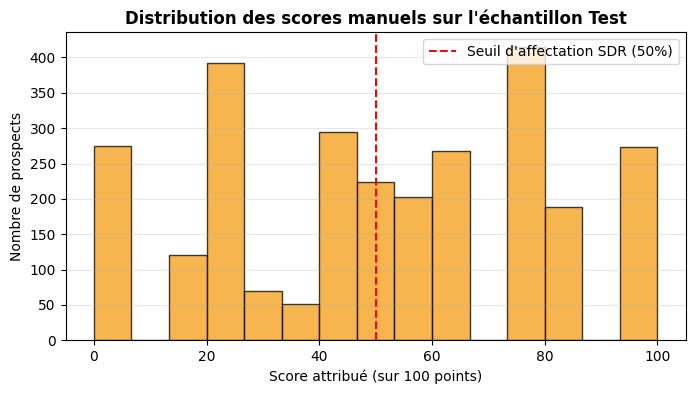

In [17]:
plt.figure(figsize=(8, 4))
plt.hist(y_scores_manual * 100, bins=15, color="#f39c12", edgecolor="black", alpha=0.75)
plt.axvline(x=50, color="red", linestyle="--", label="Seuil d'affectation SDR (50%)")
plt.title("Distribution des scores manuels sur l'échantillon Test", fontsize=12, fontweight="bold")
plt.xlabel("Score attribué (sur 100 points)")
plt.ylabel("Nombre de prospects")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()